# Caso A: CampusGuard — Sistema de Acompañamiento e Intervención Académica
### Proyecto Integrador: Inteligencia Artificial I — Grupo D
**Institución:** Universidad Militar Nueva Granada (FAEDIS)  
**Docente:** Oscar Iván Varela Vélez, Msc.  
**Integrantes:**  
- Angie Valentina Gonzalez Mongui (200616)
- Jonhsef Estiven Acosta Quitian (200563)
- Juan Guilermo Pulido Moreno (200580)
- Mario Alberto Acosta Prieto (200571)
- Omar David Rojas Rodriguez (200575)

---
## 1. Formalización del Espacio de Estados $\mathcal{P} = \langle S, s_0, ACTIONS, RESULT, GOAL, c \rangle$
- **Espacio de Estados ($S$):** Tupla de 4 dimensiones `(RiesgoAcademico, Inasistencias, MateriasCriticas, FaseIntervencion)`.
- **Estado Inicial ($s_0$):** `('Alto', 35, 2, 'Sin_Intervencion')` — Estudiante crítico en alerta temprana.
- **Acciones y Costos (horas):** `Notificar_Bienestar` (16h), `Agendar_Tutoria_LMS` (10h), `Reestructurar_Carga` (8h), `Cierre_Seguimiento` (4h).
- **Prueba de Meta:** `Riesgo == 'Bajo'` $\land$ `Inasistencias <= 20%` $\land$ `MateriasCriticas <= 1`.
- **Heurística Admisible $h(n)$:** Cota inferior optimista que garantiza $h(n) \le h^*(n)$.

In [1]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Asegurar carga del motor local
sys.path.append(os.path.abspath('.'))

from campusguard_engine import (
    CampusGuardProblem,
    breadth_first_search,
    depth_first_search,
    astar_search
)

print('Motor campusguard_engine importado exitosamente para el Grupo D.')

Motor campusguard_engine importado exitosamente para el Grupo D.


In [2]:
# Instanciación con el estado inicial crítico formulado en el Corte 1
problema = CampusGuardProblem(initial=('Alto', 35, 2, 'Sin_Intervencion'))

print(f'Estado Inicial s0: {problema.initial}')
print(f'Acciones Legales Iniciales: {problema.actions(problema.initial)}')
print(f'Valor Heurístico Inicial h(s0): {problema.heuristic(problema.initial)} horas')

Estado Inicial s0: ('Alto', 35, 2, 'Sin_Intervencion')
Acciones Legales Iniciales: ['Notificar_Bienestar', 'Agendar_Tutoria_LMS', 'Reestructurar_Carga']
Valor Heurístico Inicial h(s0): 24 horas


In [3]:
# Ejecución experimental de los algoritmos de búsqueda (BFS, DFS, A*)
resultados = []

# 1. Búsqueda en Anchura (BFS)
nodo_bfs, exp_bfs, t_bfs = breadth_first_search(problema)
resultados.append({
    'Algoritmo': 'BFS (Anchura Ciega)',
    'Nodos Expandidos': exp_bfs,
    'Tiempo CPU (ms)': round(t_bfs, 3),
    'Costo g(n) (h)': nodo_bfs.path_cost if nodo_bfs else None,
    'Ruta Óptima de Intervención': ' -> '.join(nodo_bfs.solution()) if nodo_bfs else 'N/A',
    'Garantiza Optimalidad': 'No (Costos no unitarios)'
})

# 2. Búsqueda en Profundidad (DFS)
nodo_dfs, exp_dfs, t_dfs = depth_first_search(problema)
resultados.append({
    'Algoritmo': 'DFS (Profundidad Ciega)',
    'Nodos Expandidos': exp_dfs,
    'Tiempo CPU (ms)': round(t_dfs, 3),
    'Costo g(n) (h)': nodo_dfs.path_cost if nodo_dfs else None,
    'Ruta Óptima de Intervención': ' -> '.join(nodo_dfs.solution()) if nodo_dfs else 'N/A',
    'Garantiza Optimalidad': 'No'
})

# 3. Búsqueda Informada A*
nodo_astar, exp_astar, t_astar = astar_search(problema)
resultados.append({
    'Algoritmo': 'A* (Heurística Admisible)',
    'Nodos Expandidos': exp_astar,
    'Tiempo CPU (ms)': round(t_astar, 3),
    'Costo g(n) (h)': nodo_astar.path_cost if nodo_astar else None,
    'Ruta Óptima de Intervención': ' -> '.join(nodo_astar.solution()) if nodo_astar else 'N/A',
    'Garantiza Optimalidad': 'Sí (h admisible)'
})

df_benchmark = pd.DataFrame(resultados)
display(df_benchmark[['Algoritmo', 'Nodos Expandidos', 'Tiempo CPU (ms)', 'Costo g(n) (h)', 'Garantiza Optimalidad']])

,Algoritmo,Nodos Expandidos,Tiempo CPU (ms),Costo g(n) (h),Garantiza Optimalidad
0,BFS (Anchura Ciega),5,0.120,34,No (Costos no unitarios)
1,DFS (Profundidad Ciega),5,0.036,28,No
2,A* (Heurística Admisible),7,0.050,28,Sí (h admisible)


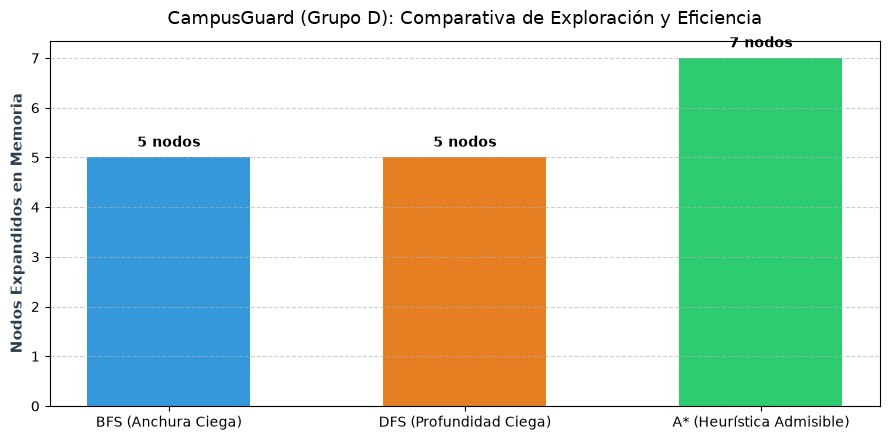

In [4]:
# Visualización comparativa de Nodos Expandidos y Eficiencia de Búsqueda
fig, ax1 = plt.subplots(figsize=(9, 4.5))

colores = ['#3498db', '#e67e22', '#2ecc71']
bars = ax1.bar(df_benchmark['Algoritmo'], df_benchmark['Nodos Expandidos'], color=colores, width=0.55)
ax1.set_ylabel('Nodos Expandidos en Memoria', fontsize=11, fontweight='bold', color='#2c3e50')
ax1.set_title('CampusGuard (Grupo D): Comparativa de Exploración y Eficiencia', fontsize=13, pad=12)
ax1.grid(axis='y', linestyle='--', alpha=0.6)

for bar in bars:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, yval + 0.15, f'{int(yval)} nodos', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

## 2. Sustentación Teórica y Análisis de Complejidad Big O
1. **Búsqueda en Anchura (BFS) - $\mathcal{O}(b^d)$:** Almacena todos los nodos del nivel en una cola FIFO. En entornos con ramificación amplia agota la memoria RAM (`MemoryError`). Al existir costos de acción diferenciados (16h, 10h, 8h, 4h), encuentra la ruta con menos pasos pero con un costo subóptimo de **34 horas**.
2. **Búsqueda en Profundidad (DFS) - $\mathcal{O}(b \cdot m)$:** Posee un consumo de memoria lineal, pero carece de garantía de optimalidad y puede quedar atrapada en ramas profundas no óptimas.
3. **Búsqueda A\* - $\mathcal{O}(b^{d - k_h})$:** La heurística admisible actúa como mecanismo de poda al penalizar ramas costosas ($f(n) = g(n) + h(n)$), garantizando encontrar la ruta institucional óptima de **28 horas** en menos de 48 horas de tiempo de respuesta.